In [1]:
# imports
import numpy as np
import matplotlib.pyplot as plt
import math
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import itertools
from statsmodels.stats.multitest import multipletests
from scipy.stats import ttest_ind_from_stats
from matplotlib.colors import to_rgba

In [ ]:
# HELPER FUNCTIONS

# for time 
def time_to_seconds(t):
    if pd.isna(t):
        return None
    # make sure it's a string
    t = str(t).strip()
    # parse HH:MM:SS (or MM:SS) to seconds
    return pd.to_timedelta(t).total_seconds()

# load dfs & first data prep
def load_ale_csv(path):
    df = pd.read_csv(path, encoding='latin1')
    
    # convert first column (time) to seconds
    df.iloc[:, 0] = df.iloc[:, 0].apply(time_to_seconds)
    
    # set as index and clean numeric data
    df = (
        df.set_index(df.columns[0])
          .rename_axis("Time [s]")
          .apply(pd.to_numeric, errors="coerce")
    )
    
    # convert seconds → hours
    df.index = df.index / 3600
    df.index.name = "Time [h]"
    
    return df

# calculate mean % stds
def mean_std_dfs(dfs):
    """
    Calculate mean and std across replicate DataFrames.
    Assumes same index and same columns.
    """
    stacked = pd.concat(dfs, keys=range(len(dfs)), names=["replicate", "Time [h]"])
    
    mean = stacked.groupby(level="Time [h]").mean()
    std = stacked.groupby(level="Time [h]").std()
    
    return mean, std

# actual plot
def plot_grouped_reactors(groups, column_config):
    fig, axes = plt.subplots(3, 2, figsize=(16, 12), sharex=True, constrained_layout=True)
    
    axes = axes.flatten()

    columns = list(column_config.keys())

    panel_labels = ["[A]", "[B]", "[C]", "[D]", "[E]", "[F]"]

    for idx, (ax, (title, dfs)) in enumerate(zip(axes, groups.items())):
        mean, std = mean_std_dfs(dfs)
        x = mean.index

        all_axes = [ax]

        for i, col in enumerate(columns):
            cfg = column_config[col]

            if i == 0:
                current_ax = ax
                current_ax.set_ylim(6, 10)
            else:
                current_ax = ax.twinx()
                current_ax.spines["right"].set_position(("outward", 60 * (i - 1)))
                all_axes.append(current_ax)

                if col == "m_temp (°C)":
                    current_ax.set_ylim(22, 30)

            current_ax.plot(
                x,
                mean[col],
                label=cfg["label"],
                color=cfg["color"]
            )

            current_ax.fill_between(
                x,
                mean[col] - std[col],
                mean[col] + std[col],
                color=cfg["color"],
                alpha=0.2
            )

            current_ax.set_ylabel(cfg["label"], color=cfg["color"])
            current_ax.tick_params(axis="y", colors=cfg["color"])

        ax.set_title(f"{panel_labels[idx]}", loc="left")
        ax.set_xlabel("Time [h]")
        ax.tick_params(axis='x', labelbottom=True)

        handles, labels = [], []
        for a in all_axes:
            h, l = a.get_legend_handles_labels()
            handles.extend(h)
            labels.extend(l)

        ax.legend(handles, labels, loc="best", fontsize=8, frameon=False)

    #plt.savefig("online_batch.png", dpi=300, bbox_inches="tight")
    
        plt.show()

In [3]:
# load data

# ALE pH7
ALE7_2 = load_ale_csv('ALE7/ALE7_210326_2.csv')
ALE7_3 = load_ale_csv('ALE7/ALE7_210326_3.csv')
ALE7_4 = load_ale_csv('ALE7/ALE7_210326_4.csv')

# ALE pH8
ALE8_2 = load_ale_csv('ALE8/ALE8_260326_2.csv')
ALE8_3 = load_ale_csv('ALE8/ALE8_260326_3.csv')
ALE8_4 = load_ale_csv('ALE8/ALE8_260326_4.csv')

# ALE pH8 noOx
ALE8_noOx_2 = load_ale_csv('ALE8_noOx/ALE8_noOx_230426_2.csv')
ALE8_noOx_3 = load_ale_csv('ALE8_noOx/ALE8_noOx_230426_3.csv')
ALE8_noOx_4 = load_ale_csv('ALE8_noOx/ALE8_noOx_230426_4.csv')

# ALE pH9
ALE9_2 = load_ale_csv('ALE9/ALE9_010426_2.csv')
ALE9_3 = load_ale_csv('ALE9/ALE9_010426_3.csv')
ALE9_4 = load_ale_csv('ALE9/ALE9_010426_4.csv')

# OG pH7
OG7_2 = load_ale_csv('OG7_2/OG7_120326_2.csv')
OG7_3 = load_ale_csv('OG7_2/OG7_120326_3.csv')
OG7_4 = load_ale_csv('OG7_2/OG7_120326_4.csv')

# OG pH8
OG8_2 = load_ale_csv('OG8/OG8_180326_2.csv')
OG8_3 = load_ale_csv('OG8/OG8_180326_3.csv')
OG8_4 = load_ale_csv('OG8/OG8_180326_4.csv')

In [ ]:
# clear up data
ALE7_4.loc[0.0, 'm_ph'] = 7.00

# remove ALE8_3 pH row
ALE8_3['m_ph'] = np.nan

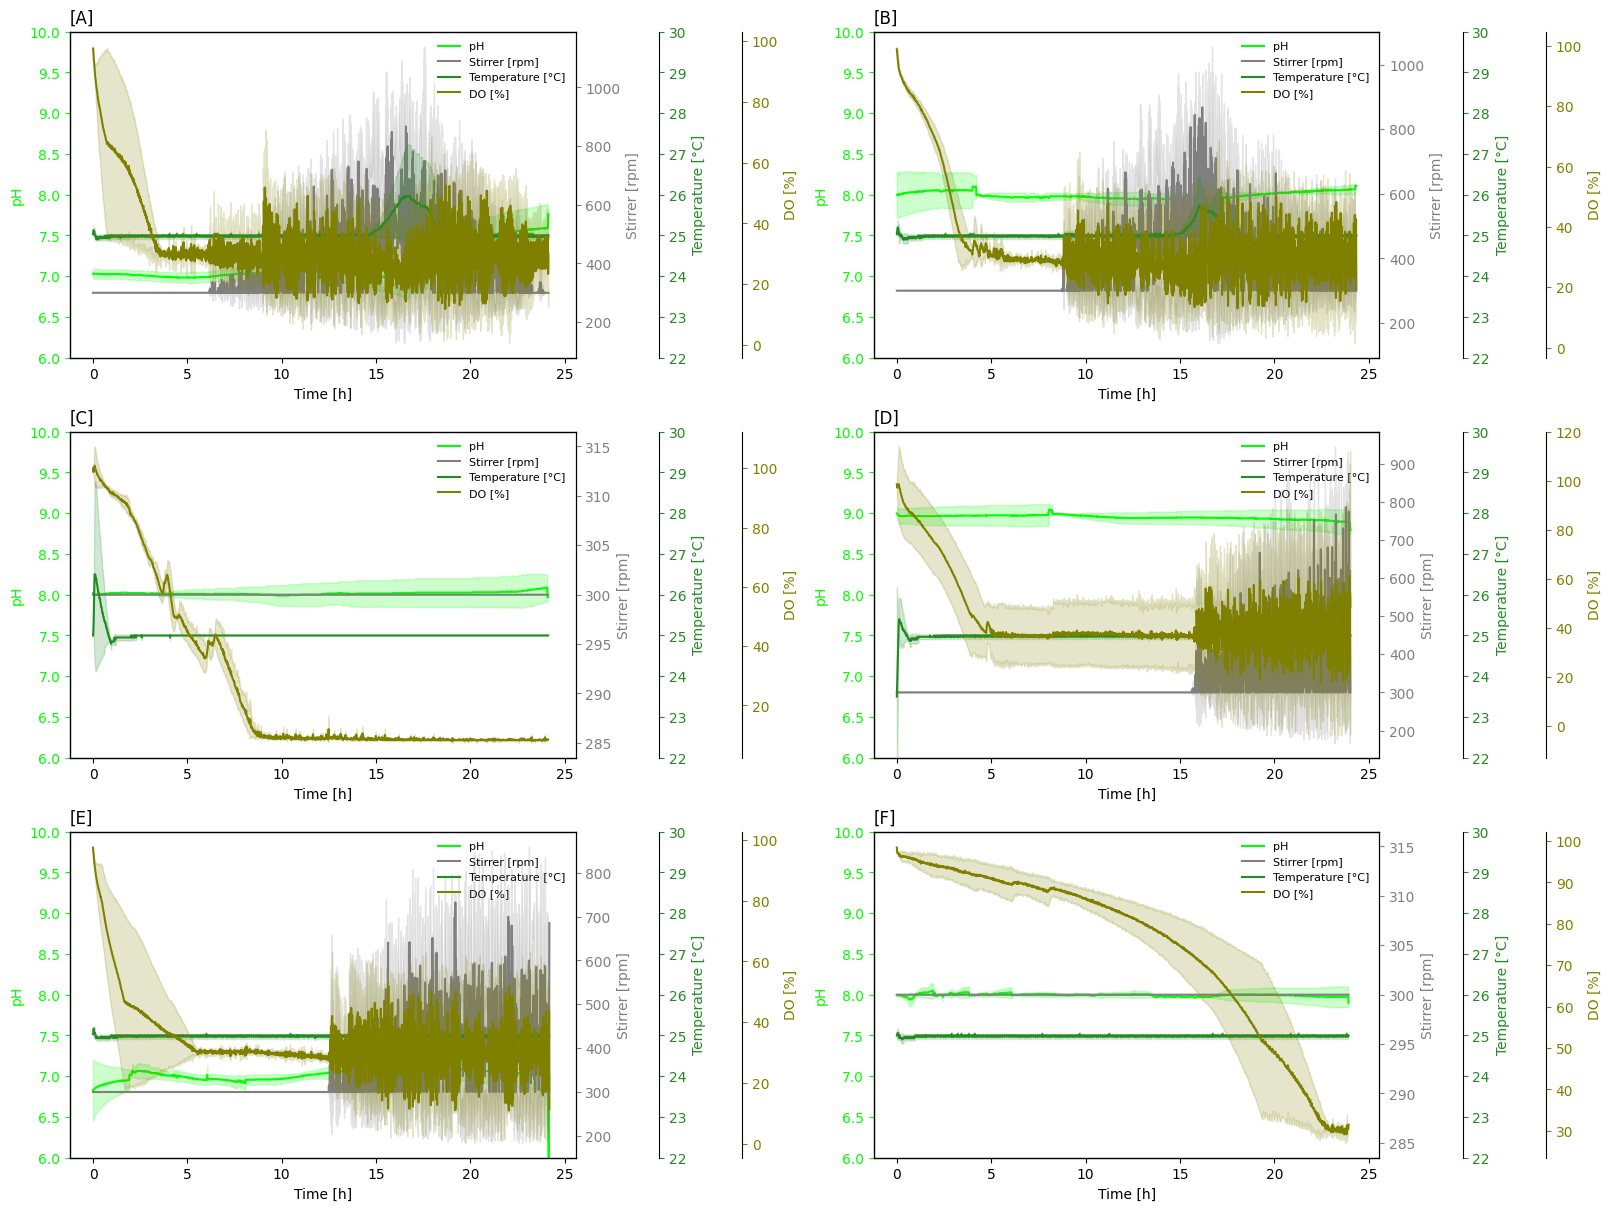

In [5]:
# define stuff & plot
# mapping
# [A] = ALE pH7
# [B] = ALE pH8
# [C] = ALE pH8 noOx
# [D] = ALE pH9
# [E] = OG pH7
# [F] = OG pH8

groups = {
    "ALE pH7": [ALE7_2, ALE7_3, ALE7_4],
    "ALE pH8": [ALE8_2, ALE8_3, ALE8_4],
    "ALE pH8 noOx": [ALE8_noOx_2, ALE8_noOx_4], # removed ALE8_noOx_3
    "ALE pH9": [ALE9_2, ALE9_3, ALE9_4],
    "OG pH7": [OG7_2, OG7_3, OG7_4],
    "OG pH8": [OG8_2, OG8_3, OG8_4],
}

column_config = {
    "m_ph": {
        "label": "pH",
        "color": "lime"
    },
    "m_stirrer (rpm)": {
        "label": "Stirrer [rpm]",
        "color": "0.5"  # gray
    },
    "m_temp (°C)": {
        "label": "Temperature [°C]",
        "color": "forestgreen"
    },
    "m_do2 (%)": {
        "label": "DO [%]",
        "color": "olive"
    }
}

plot_grouped_reactors(groups, column_config)

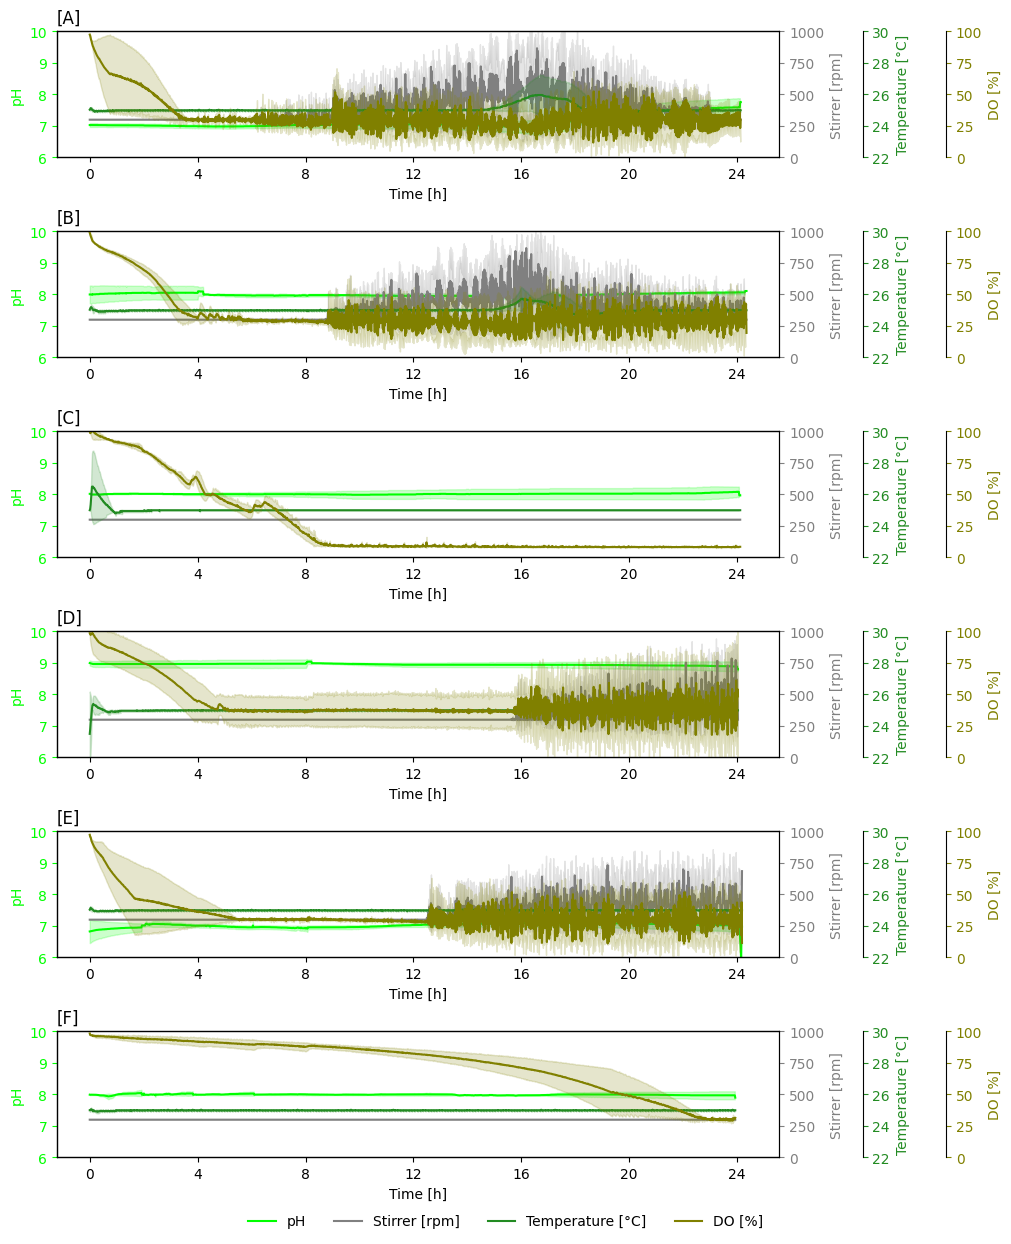

In [ ]:
# PLOT 6x1
def plot_grouped_reactors_6x1(groups, column_config):
    fig, axes = plt.subplots(6, 1, figsize=(10, 12), sharex=True, constrained_layout=True)
    
    axes = axes.flatten()

    columns = list(column_config.keys())

    panel_labels = ["[A]", "[B]", "[C]", "[D]", "[E]", "[F]"]

    for idx, (ax, (title, dfs)) in enumerate(zip(axes, groups.items())):
        mean, std = mean_std_dfs(dfs)
        x = mean.index

        all_axes = [ax]

        for i, col in enumerate(columns):
            cfg = column_config[col]

            # create/select axis
            if i == 0:
                current_ax = ax
            else:
                current_ax = ax.twinx()
                current_ax.spines["right"].set_position(("outward", 60 * (i - 1)))
                all_axes.append(current_ax)

            # apply axis settins
            if "ylim" in cfg:
                current_ax.set_ylim(*cfg["ylim"])
            
            if "yticks" in cfg:
                current_ax.set_yticks(cfg["yticks"])

            else:
                current_ax = ax.twinx()
                current_ax.spines["right"].set_position(("outward", 60 * (i - 1)))
                all_axes.append(current_ax)

            current_ax.plot(
                x,
                mean[col],
                label=cfg["label"],
                color=cfg["color"]
            )

            current_ax.fill_between(
                x,
                mean[col] - std[col],
                mean[col] + std[col],
                color=cfg["color"],
                alpha=0.2
            )

            current_ax.set_ylabel(cfg["label"], color=cfg["color"])
            current_ax.tick_params(axis="y", colors=cfg["color"])

        ax.set_title(f"{panel_labels[idx]}", loc="left")
        ax.set_xlabel("Time [h]")
        ax.tick_params(axis='x', labelbottom=True)
        ax.set_xticks([0, 4, 8, 12, 16, 20, 24])

        handles, labels = [], []
        for a in all_axes:
            h, l = a.get_legend_handles_labels()
            handles.extend(h)
            labels.extend(l)

    fig.legend(
        handles,
        labels,
        loc="lower center",
        ncol=4,
        frameon=False,
        bbox_to_anchor=(0.5, -0.03)
    )
    
    #plt.savefig("online700mL_paper.tiff", dpi=1000, bbox_inches="tight")
    plt.show()

# define stuff & plot
# mapping
# [A] = ALE pH7
# [B] = ALE pH8
# [C] = ALE pH8 noOx
# [D] = ALE pH9
# [E] = OG pH7
# [F] = OG pH8

groups = {
    "ALE pH7": [ALE7_2, ALE7_3, ALE7_4],
    "ALE pH8": [ALE8_2, ALE8_3, ALE8_4],
    "ALE pH8 noOx": [ALE8_noOx_2, ALE8_noOx_4], # removed ALE8_noOx_3
    "ALE pH9": [ALE9_2, ALE9_3, ALE9_4],
    "OG pH7": [OG7_2, OG7_3, OG7_4],
    "OG pH8": [OG8_2, OG8_3, OG8_4],
}

column_config = {
    "m_ph": {
        "label": "pH",
        "color": "lime",
        'ylim': (6, 10),
        'yticks': (6, 7, 8, 9, 10)
    },
    "m_stirrer (rpm)": {
        "label": "Stirrer [rpm]",
        "color": "0.5",  # gray
        'ylim': (0, 1000),
        'yticks': (0, 250, 500, 750, 1000)
    },
    "m_temp (°C)": {
        "label": "Temperature [°C]",
        "color": "forestgreen",
        'ylim': (22, 30),
        'yticks': (22, 24, 26, 28, 30)
    },
    "m_do2 (%)": {
        "label": "DO [%]",
        "color": "olive",
        'ylim': (0, 100),
        'yticks': (0, 25, 50, 75, 100)
    }
}

plot_grouped_reactors_6x1(groups, column_config)